## Dependencies

In [1]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.inference import evaluation
from libs.inference import categorical

Total combinations of features: 1023


## Setup

In [3]:
VERSION = 3
MODEL = 'classification'
DIR = f'../../results/v{VERSION}/gender/predictions_ch/best_models/eval_best_results_{MODEL}.csv'
METRIC = evaluation.METRIC[MODEL]
ASCENDING = evaluation.METRICS_SORT_ASC[METRIC]
REGRESSOR = MODEL == 'regression'

PLOT_DIR = f'../../results/v{VERSION}/gender/predictions_ch_others/plots'
ios.validate_path(PLOT_DIR)

print(f'{'Regression' if REGRESSOR else 'Classification'} | Metric: {METRIC} | Ascending: {ASCENDING}')

Classification | Metric: test_auc | Ascending: False


In [4]:
vis.sns_paper_style()

## Data

In [5]:
df_best_results = ios.load_csv(DIR)
df_best_results.shape

(3, 36)

In [6]:
cols = ['y','features_id','features','nfeatures', METRIC,'rs' ,'best_per_rs','best_overall']
df_best_results[cols].sort_values(METRIC, ascending=ASCENDING)

,y,features_id,features,nfeatures,test_auc,rs,best_per_rs,best_overall
0,gender_mean,607,"['gender_n', 'gender_nw', 'mean_ngender_rn', '...",5,0.970959,2,True,True
1,gender_median,251,"['ngender_r', 'single_char', 'mean_ngender_rn'...",4,0.965516,1,True,False
2,gender_mean,336,"['gender_n', 'gender_nw', 'mean_ngender_rn', '...",4,0.942794,3,True,False


## Per run

Run id: 1
../../results/v3/gender/predictions_ch/comparison/rs1/classification/_median/cut_4/median_251_4


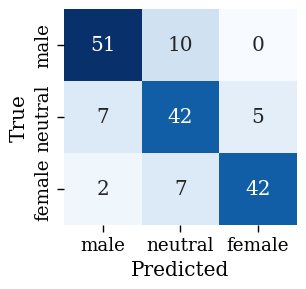

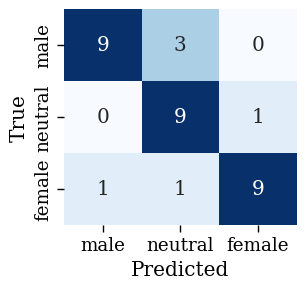

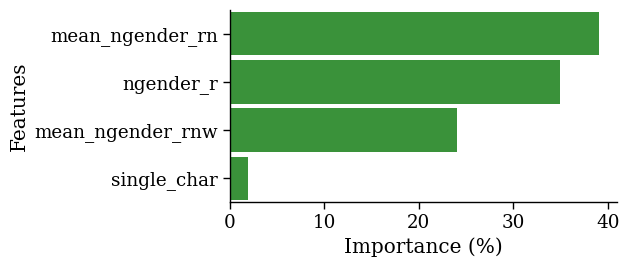

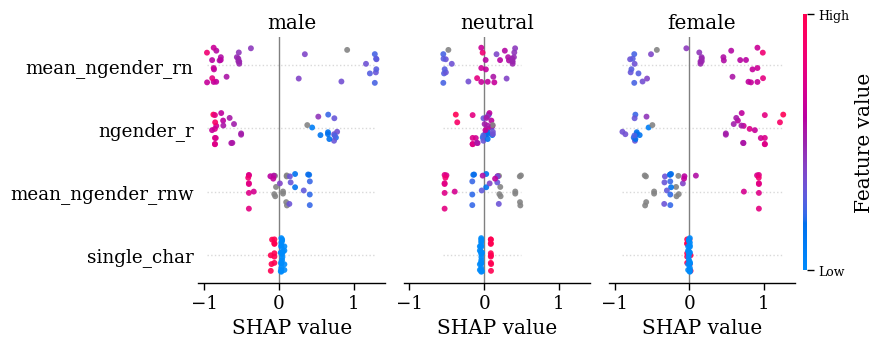

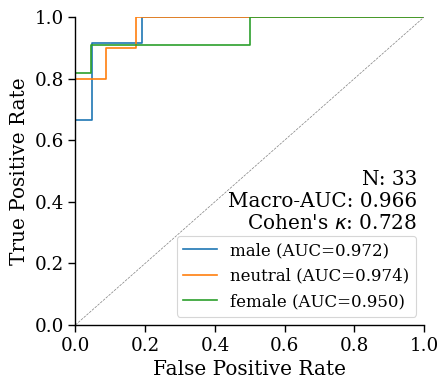

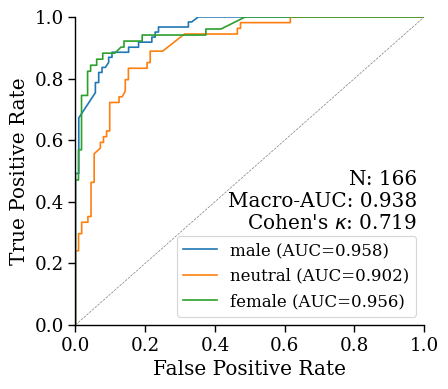

In [7]:
rs = 1
tmp_run = df_best_results.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = tmp_run.iloc[0].best_overall
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

fh = 2.5
fhc = 2.8
fhs = 3.2
spw = 3.
spr = 4.5
fhr = 4
vis.replot_confusion_matrix(f_name_rs, test_only=False, figure_width=spw, figure_height=fhc, cbar=False)
vis.replot_confusion_matrix(f_name_rs, test_only=True, figure_width=spw, figure_height=fhc, cbar=False)
vis.replot_importance(f_name_rs, regressor=REGRESSOR, figure_width=5., figure_height=fh)
vis.replot_shap(f_name_rs, regressor=REGRESSOR, subplot_width=2.6, figure_height=fhs)
vis.replot_rocauc(f_name_rs, test_only=True, figure_width=spr, figure_height=fhr)
vis.replot_rocauc(f_name_rs, test_only=False, figure_width=spr, figure_height=fhr)

Run id: 2 (best overall)
../../results/v3/gender/predictions_ch/comparison/rs2/classification/_mean/cut_1/mean_607_1


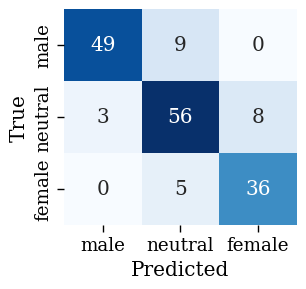

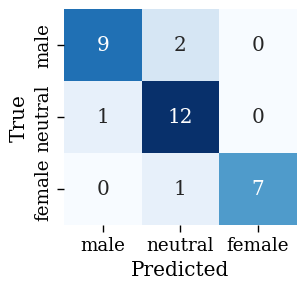

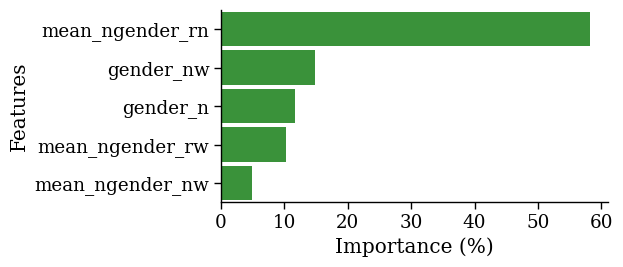

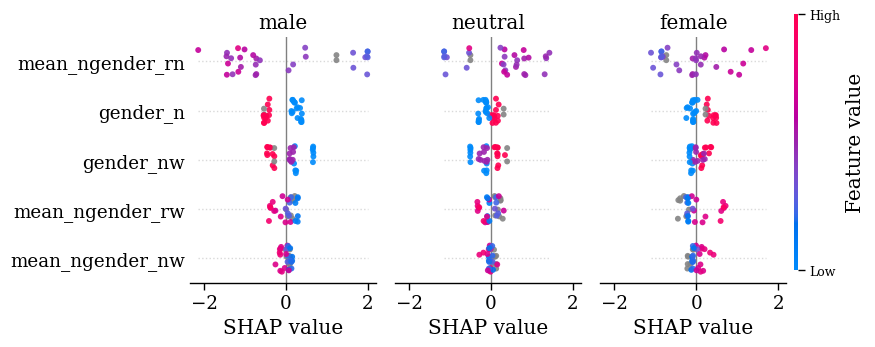

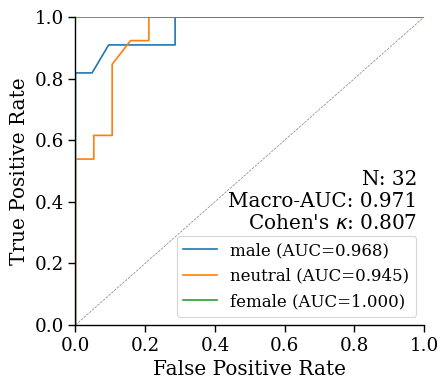

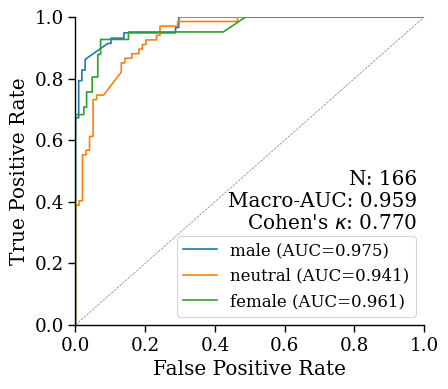

In [8]:
rs = 2
tmp_run = df_best_results.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = tmp_run.iloc[0].best_overall
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

fh = 2.5
fhc = 2.8
fhs = 3.2
spw = 3.
spr = 4.5
fhr = 4
vis.replot_confusion_matrix(f_name_rs, test_only=False, figure_width=spw, figure_height=fhc, cbar=False)
vis.replot_confusion_matrix(f_name_rs, test_only=True, figure_width=spw, figure_height=fhc, cbar=False)
vis.replot_importance(f_name_rs, regressor=REGRESSOR, figure_width=5., figure_height=fh)
vis.replot_shap(f_name_rs, regressor=REGRESSOR, subplot_width=2.6, figure_height=fhs)
vis.replot_rocauc(f_name_rs, test_only=True, figure_width=spr, figure_height=fhr)
vis.replot_rocauc(f_name_rs, test_only=False, figure_width=spr, figure_height=fhr)

Run id: 3
../../results/v3/gender/predictions_ch/comparison/rs3/classification/_mean/cut_3/mean_336_3


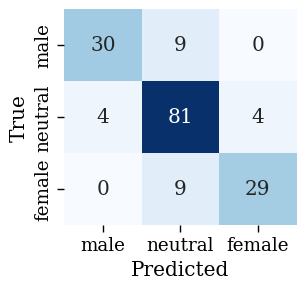

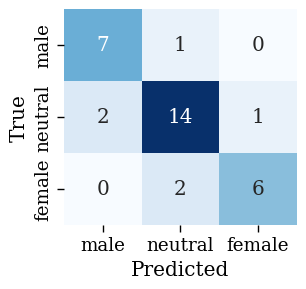

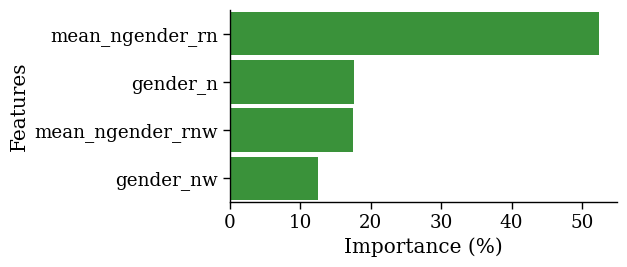

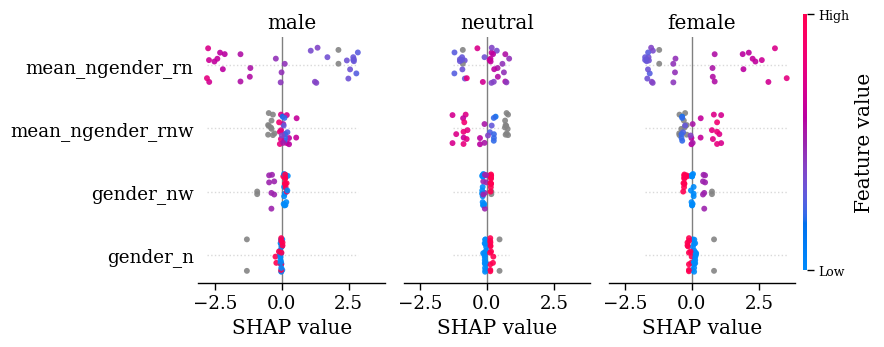

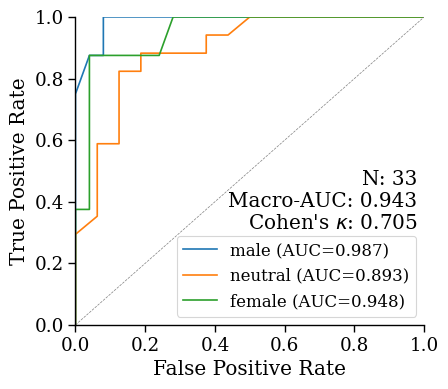

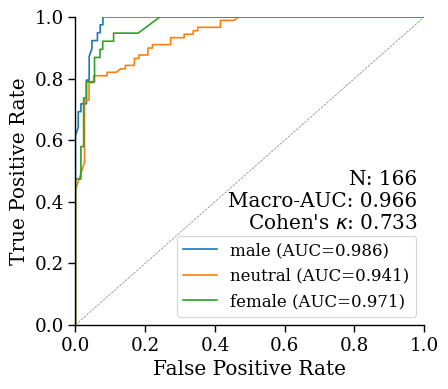

In [9]:
rs = 3
tmp_run = df_best_results.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = tmp_run.iloc[0].best_overall
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

fh = 2.5
fhc = 2.8
fhs = 3.2
spw = 3.
spr = 4.5
fhr = 4
vis.replot_confusion_matrix(f_name_rs, test_only=False, figure_width=spw, figure_height=fhc, cbar=False)
vis.replot_confusion_matrix(f_name_rs, test_only=True, figure_width=spw, figure_height=fhc, cbar=False)
vis.replot_importance(f_name_rs, regressor=False, figure_width=5., figure_height=fh)
vis.replot_shap(f_name_rs, regressor=False, subplot_width=2.6, figure_height=fhs)
vis.replot_rocauc(f_name_rs, test_only=True, figure_width=spr, figure_height=fhr)
vis.replot_rocauc(f_name_rs, test_only=False, figure_width=spr, figure_height=fhr)

# Comparision with other tools

In [10]:
FN_CH_CLASS_SAMPLES = f'../../results/v{VERSION}/gender/predictions_ch/comparison/rs2/classification/_mean/cut_1/ground_truth_MLsampled.csv'
FN_CH_CLASS = f'../../results/v{VERSION}/gender/predictions_ch/best_models/rs2/CNKI_uniqueChineseAllGivenNames_gender_class_mean_607_1.csv'

CH_OTHERS_DIR = f'../../results/v{VERSION}/gender/predictions_ch_others/'
FN_CH_OTHERS = f'{CH_OTHERS_DIR}/<OTHER_PROVIDER>/chinese_given_names_gendered.csv'
FN_CH_CLAUDE = FN_CH_OTHERS.replace('<OTHER_PROVIDER>', 'claude')
FN_CH_GPT = FN_CH_OTHERS.replace('<OTHER_PROVIDER>', 'gpt')
FN_CH_NAMSOR = FN_CH_OTHERS.replace('<OTHER_PROVIDER>', 'namsor')

In [11]:
METHOD_CH_ORDER = ['ch_gender_claude', 'ch_gender_gpt', 'ch_gender_namsor', 'pred_label', 'gender_mean']
METHOD_CH_LABELS_SHORT = {
        "gender_mean": "GT",
        'pred_label': "(CH)",
        "ch_gender_claude": "Clau.",
        "ch_gender_gpt": "GPT",
        "ch_gender_namsor": "Nam.",
    }

METHOD_CH_LABELS = {
        'gender_mean': "Ground Truth (GT)",
        "ch_gender_claude": "Claude Opus 4.6",
        "ch_gender_gpt": "GPT-5.4",
        "ch_gender_namsor": "Namsor $_{(Genderize~Name~Geo)}$",
        "pred_label": "Ours (CH)"
    }


In [12]:
df_samples = ios.load_csv(FN_CH_CLASS_SAMPLES)
df_test = df_samples.query("ml_sample=='test'")
df_test.head()

,givenname,gender_mean,single_char,ngender_r,ngender_n,gender_n,gender_w,gender_nw,mean_ngender_rnw,mean_ngender_rn,mean_ngender_rw,mean_ngender_nw,ml_sample
2,仅,neutral,True,0.60040,0.545362,female,unknown,female,NaN,0.572881,NaN,NaN,test
15,桓,male,True,0.11570,0.538696,female,unknown,female,NaN,0.327198,NaN,NaN,test
17,润,neutral,True,0.48830,0.547711,female,unknown,female,NaN,0.518005,NaN,NaN,test
22,甄,neutral,True,0.73150,0.534606,female,unknown,female,NaN,0.633053,NaN,NaN,test
27,童,neutral,True,0.46905,0.456021,male,unknown,male,NaN,0.462535,NaN,NaN,test


In [13]:
df_class_pred = ios.load_csv(FN_CH_CLASS, index_col=0)
df_class_pred.head()

,givenname,gender_n,gender_nw,mean_ngender_rn,mean_ngender_rw,mean_ngender_nw,single_char,pred_code,pred_label
0,㑇,male,male,NaN,NaN,NaN,True,0,male
1,㑊,male,male,NaN,NaN,NaN,True,0,male
2,㕮,male,male,NaN,NaN,NaN,True,0,male
3,㘎,male,male,NaN,NaN,NaN,True,0,male
4,㙍,male,male,NaN,NaN,NaN,True,0,male


In [14]:
df_class_pred_test = df_class_pred.query("givenname.isin(@df_test.givenname)")
df_class_pred_test.shape

(32, 9)

In [15]:
fn = f'{CH_OTHERS_DIR}/aps_chinese_given_names.csv'
ios.to_csv(df_class_pred_test['givenname'], fn)

In [16]:
df_aps_ch_claude = ios.load_csv(FN_CH_CLAUDE, index_col=0).set_index('givenname')
df_aps_ch_gpt = ios.load_csv(FN_CH_GPT, index_col=0).set_index('givenname')
df_aps_ch_namsor = ios.load_csv(FN_CH_NAMSOR, index_col=0).set_index('givenname')
df_aps_ch_namsor.rename(columns={'likelyGender': 'ch_gender_namsor'}, inplace=True)

In [17]:
df_ch_genders = df_test[['givenname','gender_mean','gender_n','gender_w']].set_index('givenname').join(df_class_pred_test[['givenname','pred_label']].set_index('givenname'), how='inner')
df_ch_genders = df_ch_genders.join(df_aps_ch_claude).join(df_aps_ch_gpt).join(df_aps_ch_namsor['ch_gender_namsor'])
df_ch_genders.head(2)

,gender_mean,gender_n,gender_w,pred_label,ch_gender_claude,ch_gender_gpt,ch_gender_namsor
givenname,,,,,,,
仅,neutral,female,unknown,neutral,neutral,neutral,male
桓,male,female,unknown,male,male,male,male


In [18]:
# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_ch = categorical.pairwise_agreement(df_ch_genders, METHOD_CH_ORDER)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_gt_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_ch = categorical.pairwise_kappa(df_ch_genders, METHOD_CH_ORDER)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_gt_ch.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,ch_gender_claude,ch_gender_gpt,ch_gender_namsor,pred_label,gender_mean
ch_gender_claude,1.00,0.78,0.41,0.91,0.91
ch_gender_gpt,0.78,1.00,0.41,0.69,0.78
ch_gender_namsor,0.41,0.41,1.00,0.38,0.44
pred_label,0.91,0.69,0.38,1.00,0.88
gender_mean,0.91,0.78,0.44,0.88,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,ch_gender_claude,ch_gender_gpt,ch_gender_namsor,pred_label,gender_mean
ch_gender_claude,1.00,0.68,0.16,0.86,0.86
ch_gender_gpt,0.68,1.00,0.17,0.54,0.68
ch_gender_namsor,0.16,0.17,1.00,0.17,0.22
pred_label,0.86,0.54,0.17,1.00,0.81
gender_mean,0.86,0.68,0.22,0.81,1.00


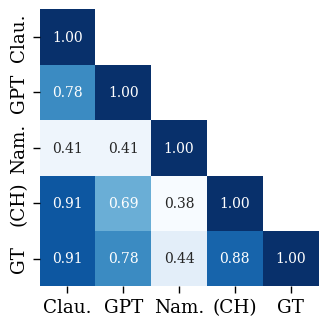

../../results/v3/gender/predictions_ch_others/plots/ch_gender_pairwise_agreement.pdf


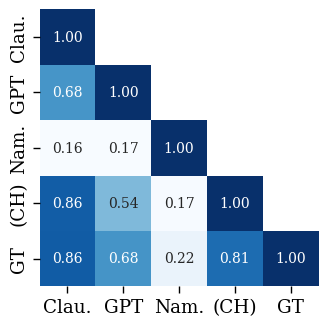

../../results/v3/gender/predictions_ch_others/plots/ch_gender_pairwise_kappa.pdf


In [19]:
for kind, arr in {'agreement':agreement_gt_ch,'kappa':kappa_gt_ch}.items():
    arr = arr.to_numpy()
    arr[categorical.np.triu_indices(arr.shape[0], k=1)] = categorical.np.nan
    fn = f'{PLOT_DIR}/ch_gender_pairwise_{kind}.pdf'
    vis.plot_confusion_matrix(arr, [METHOD_CH_LABELS_SHORT[m] for m in METHOD_CH_ORDER], 
                            title=None,
                            xlabel=None,
                            ylabel=None,
                            cbar=False,
                            annot_kws={'fontsize': 10},
                            cmap='Blues', figsize=(3.6, 3.6),
                            fn=fn,
                            )
    print(fn)

../../results/v3/gender/predictions_ch_others/plots/ch_gender_cm_recall.pdf
../../results/v3/gender/predictions_ch_others/plots/ch_gender_cm_precision.pdf
../../results/v3/gender/predictions_ch_others/plots/ch_gender_cm_counts.pdf


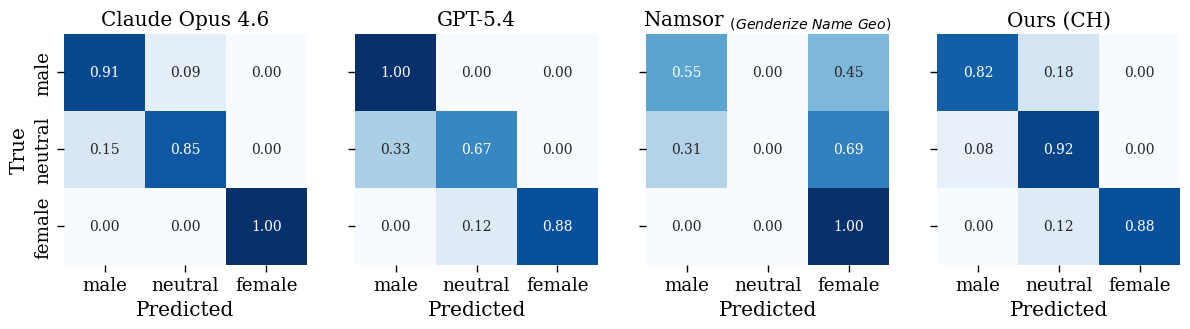

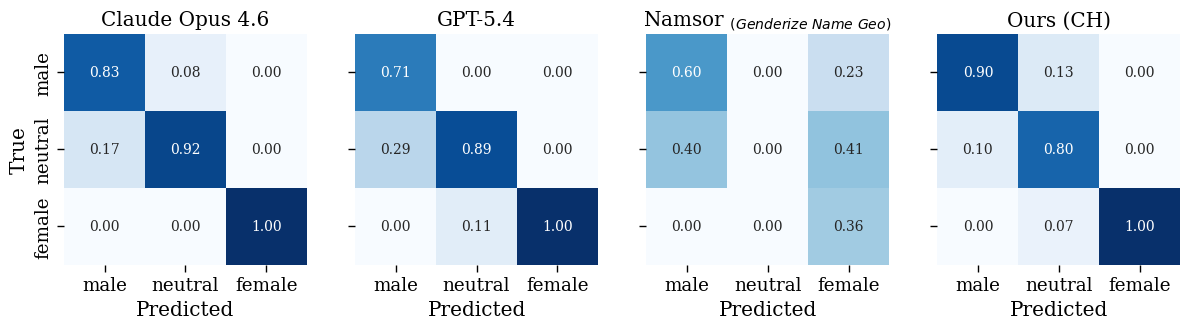

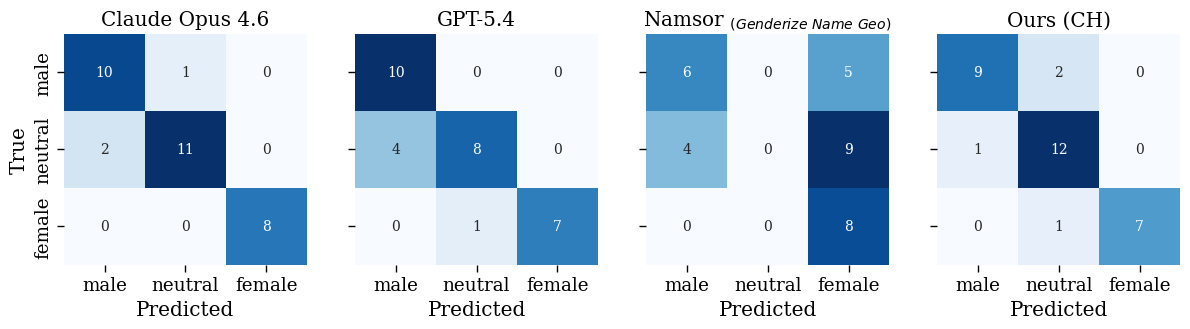

In [20]:
col_ref = 'gender_mean'

methods = [c for c in METHOD_CH_ORDER if c != col_ref]
nrows = 1
ncols = len(methods)
width = 3.6
height = 3.0

for norm, metric in {'true':'Recall', 'pred':'Precision', None:'Counts'}.items():
    
    fig, axes = vis.create_plot(nrows=nrows, ncols=ncols, figsize=(width * ncols, height * nrows), sharex=True, sharey=True)
    
    for icol, col in enumerate(methods):
        
        ax = axes[icol]
        vmin, vmax = (0, 1) if norm else (None, None)
        cbar = False
        labels = categorical.GENDER_LABELS_3
        cm = categorical.confusion_matrix(y_true=df_ch_genders[col_ref], y_pred=df_ch_genders[col], labels=labels, normalize=norm)
        vis.plot_confusion_matrix(cm, labels, None, 
                                cbar=cbar, 
                                vmin=vmin, vmax=vmax, 
                                ax=ax,
                                finalize=False)
        ax.set_xlabel("Predicted")
        ax.set_title(f"{METHOD_CH_LABELS[col]}")
        
    axes[0].set_ylabel("True")
    fn = f'{PLOT_DIR}/ch_gender_cm_{metric.lower()}.pdf'
    fig.savefig(fn, bbox_inches='tight', dpi=vis.FIG_DPI)
    print(fn)
    
